# Mortality overview across distance space (2 ambulances, all bcas)


In [ ]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

df = pd.read_csv(_root / "data_cluster/resource_grid/results.csv")
df = df[df["n_amb_r1_to_ccp"] == 2].reset_index(drop=True)
print(f"Loaded {len(df)} runs (2 ambulances)")

POLICIES = {
    "Stovepipe": (0, 0),
    "Facility": (1, 0),
    "Ambulance": (0, 1),
    "Both": (1, 1),
}

data = {}
for label, (fac, amb) in POLICIES.items():
    sub = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)]
    agg = sub.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].mean().reset_index()
    pivot = agg.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="death_rate_T1_BCAS")
    data[label] = pivot
    print(f"{label}: {len(sub)} runs, {pivot.shape[0]}x{pivot.shape[1]} grid")

cols = data["Stovepipe"].columns.values
rows = data["Stovepipe"].index.values


## Mean T1 mortality per policy (smoothed, all bcas aggregated)


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

vmin = min(d.values.min() for d in data.values())
vmax = max(d.values.max() for d in data.values())

for ax, (label, pivot) in zip(axes.flat, data.items()):
    smoothed = gaussian_filter(pivot.values.astype(float), sigma=1.0)
    im = ax.imshow(smoothed, cmap="YlOrRd", origin="lower", aspect="auto",
                   interpolation="bicubic", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows)
    ax.set_xlabel("Own R1 distance (min)")
    ax.set_ylabel("Neighbor R1 distance (min)")
    ax.set_title(label, fontsize=14, fontweight="bold")
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle("Mean T1 BCAS mortality (smoothed, all bcas rates)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


## Fraction of seeds where policy improves over stovepipe (delta < 0)


In [ ]:
MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]
stove_raw = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)]

pol_defs = [
    ("Facility", 1, 0),
    ("Ambulance", 0, 1),
    ("Both", 1, 1),
]

fig, axes = plt.subplots(1, 3, figsize=(24, 8))

for ax, (label, fac, amb) in zip(axes, pol_defs):
    pol_raw = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)]

    merged = stove_raw[MATCH_COLS + ["bcas_rate", "death_rate_T1_BCAS"]].merge(
        pol_raw[MATCH_COLS + ["bcas_rate", "death_rate_T1_BCAS"]],
        on=MATCH_COLS + ["bcas_rate"], suffixes=("_stv", "_pol"))
    merged["delta"] = merged["death_rate_T1_BCAS_pol"] - merged["death_rate_T1_BCAS_stv"]
    merged["helps"] = merged["delta"] < 0

    grid = merged.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]).agg(
        frac_helps=("helps", "mean"),
        n_helps=("helps", "sum"),
        n_total=("helps", "size"),
    ).reset_index()

    pivot_frac = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="frac_helps")
    pivot_n = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="n_helps")

    im = ax.imshow(pivot_frac.values, cmap="YlGn", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=0, vmax=1)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, fontsize=7)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows, fontsize=7)
    ax.set_xlabel("Own R1 distance (min)")
    ax.set_ylabel("Neighbor R1 distance (min)")
    ax.set_title(f"{label} helps (delta < 0)", fontsize=13, fontweight="bold")

    for i in range(len(rows)):
        for j in range(len(cols)):
            frac = pivot_frac.values[i, j]
            n = int(pivot_n.values[i, j])
            color = "white" if frac > 0.5 else "black"
            ax.text(j, i, f"{n}", ha="center", va="center", fontsize=6, fontweight="bold", color=color)

    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle("Fraction of seeds where policy helps (all bcas rates aggregated)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## Facility vs Stovepipe (bcas 0.035–0.065)


Filtered to 202800 runs (bcas 0.035-0.065)


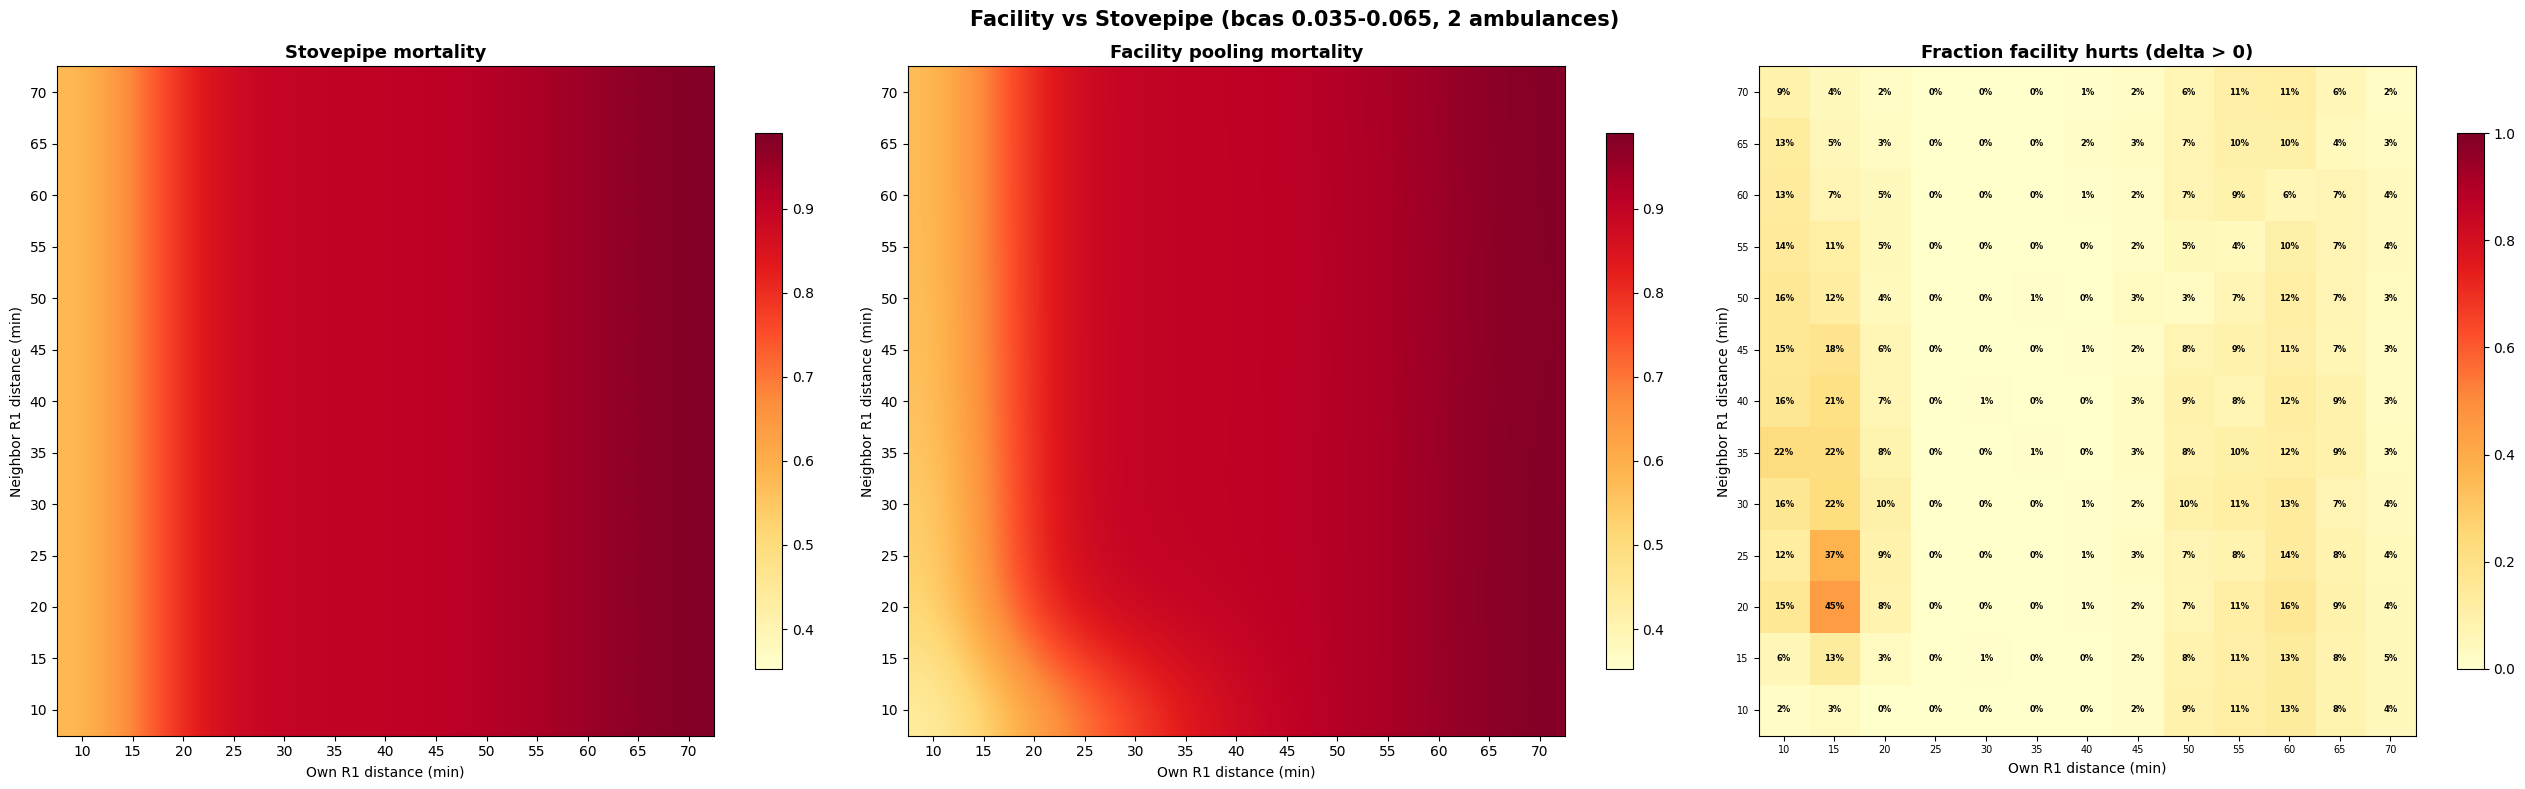

In [8]:
df_mid = df[(df["bcas_rate"] >= 0.035) & (df["bcas_rate"] <= 0.065)].copy()
print(f"Filtered to {len(df_mid)} runs (bcas 0.035-0.065)")

stove_mid = df_mid[(df_mid["facility_eligibility"] == 0) & (df_mid["ambulance_eligibility"] == 0)]
fac_mid = df_mid[(df_mid["facility_eligibility"] == 1) & (df_mid["ambulance_eligibility"] == 0)]

pivot_stove = stove_mid.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].mean().reset_index()
pivot_stove = pivot_stove.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="death_rate_T1_BCAS")

pivot_fac = fac_mid.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].mean().reset_index()
pivot_fac = pivot_fac.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="death_rate_T1_BCAS")

# Fraction facility hurts
MATCH_COLS_MID = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]
merged_mid = stove_mid[MATCH_COLS_MID + ["bcas_rate", "death_rate_T1_BCAS"]].merge(
    fac_mid[MATCH_COLS_MID + ["bcas_rate", "death_rate_T1_BCAS"]],
    on=MATCH_COLS_MID + ["bcas_rate"], suffixes=("_stv", "_fac"))
merged_mid["delta"] = merged_mid["death_rate_T1_BCAS_fac"] - merged_mid["death_rate_T1_BCAS_stv"]
merged_mid["hurts"] = merged_mid["delta"] > 0

grid_hurts = merged_mid.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]).agg(
    frac_hurts=("hurts", "mean"),
    n_hurts=("hurts", "sum"),
    n_total=("hurts", "size"),
).reset_index()
pivot_hurts_frac = grid_hurts.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="frac_hurts")
pivot_hurts_n = grid_hurts.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="n_hurts")

vmin_mort = min(pivot_stove.values.min(), pivot_fac.values.min())
vmax_mort = max(pivot_stove.values.max(), pivot_fac.values.max())

fig, axes = plt.subplots(1, 3, figsize=(26, 8))

# Stovepipe mortality
sm = gaussian_filter(pivot_stove.values.astype(float), sigma=1.0)
im0 = axes[0].imshow(sm, cmap="YlOrRd", origin="lower", aspect="auto",
                     interpolation="bicubic", vmin=vmin_mort, vmax=vmax_mort)
axes[0].set_xticks(range(len(cols))); axes[0].set_xticklabels(cols)
axes[0].set_yticks(range(len(rows))); axes[0].set_yticklabels(rows)
axes[0].set_xlabel("Own R1 distance (min)")
axes[0].set_ylabel("Neighbor R1 distance (min)")
axes[0].set_title("Stovepipe mortality", fontsize=13, fontweight="bold")
plt.colorbar(im0, ax=axes[0], shrink=0.8)

# Facility mortality
sm_fac = gaussian_filter(pivot_fac.values.astype(float), sigma=1.0)
im1 = axes[1].imshow(sm_fac, cmap="YlOrRd", origin="lower", aspect="auto",
                     interpolation="bicubic", vmin=vmin_mort, vmax=vmax_mort)
axes[1].set_xticks(range(len(cols))); axes[1].set_xticklabels(cols)
axes[1].set_yticks(range(len(rows))); axes[1].set_yticklabels(rows)
axes[1].set_xlabel("Own R1 distance (min)")
axes[1].set_ylabel("Neighbor R1 distance (min)")
axes[1].set_title("Facility pooling mortality", fontsize=13, fontweight="bold")
plt.colorbar(im1, ax=axes[1], shrink=0.8)

# Fraction facility hurts
im2 = axes[2].imshow(pivot_hurts_frac.values, cmap="YlOrRd", origin="lower", aspect="auto",
                     interpolation="nearest", vmin=0, vmax=1)
axes[2].set_xticks(range(len(cols))); axes[2].set_xticklabels(cols, fontsize=7)
axes[2].set_yticks(range(len(rows))); axes[2].set_yticklabels(rows, fontsize=7)
axes[2].set_xlabel("Own R1 distance (min)")
axes[2].set_ylabel("Neighbor R1 distance (min)")
axes[2].set_title("Fraction facility hurts (delta > 0)", fontsize=13, fontweight="bold")
for i in range(len(rows)):
    for j in range(len(cols)):
        frac = pivot_hurts_frac.values[i, j]
        color = "white" if frac > 0.5 else "black"
        axes[2].text(j, i, f"{frac:.0%}", ha="center", va="center", fontsize=6, fontweight="bold", color=color)
plt.colorbar(im2, ax=axes[2], shrink=0.8)

plt.suptitle("Facility vs Stovepipe (bcas 0.035-0.065, 2 ambulances)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()
